# Electricity | Classificação do preço da eletricidade em NSW (queda/alta)

**Disciplina:** Introdução ao Aprendizado de Máquina

**Integrantes:** Estevan Hernandes (CP3031187), Marcus Vinicius (CP3031721) e Pedro Henrique (CP3029352)

**Objetivo:** Classificar se o preço da energia em New South Wales está abaixo (`down`) ou acima (`up`) da média móvel recente. A classe positiva das classificações será **`down` (queda)**.

## 1. Base e preparação

### 1.1 Origem e descrição

**Fonte:** OpenML - [Electricity, dataset 151](https://www.openml.org/d/151). Licença registrada como *Public*. Referência: Harries, M. (1999). *Splice-2 Comparative Evaluation: Electricity Pricing*. Technical Report, University of New South Wales.

**O que cada linha representa:** um período de **30 minutos** do mercado de eletricidade australiano, com dados de New South Wales (NSW) e Victoria (VIC), de **maio de 1996 a dezembro de 1998**.

**Divisão fornecida pelo professor:**

| Conjunto | Registros | Período |
| --- | ---: | --- |
| Treino | 36.240 | parte inicial da sequência |
| Teste | 9.072 | parte final da sequência |

**Atributos:**

| Variável | Tipo | Descrição |
| --- | --- | --- |
| `date_normalized` | numérica (temporal) | Data normalizada entre 0 e 1 |
| `day` | categórica | Dia da semana (`day_1` a `day_7`) |
| `period_index` | inteira (temporal, cíclica) | Período de meia hora no dia (1 a 48) |
| `nsw_price_normalized` | numérica contínua | Preço normalizado em NSW |
| `nsw_demand_normalized` | numérica contínua | Demanda normalizada em NSW |
| `vic_price_normalized` | numérica contínua | Preço normalizado em VIC |
| `vic_demand_normalized` | numérica contínua | Demanda normalizada em VIC |
| `transfer_normalized` | numérica contínua | Transferência programada entre os estados |
| `nsw_price_class` | **alvo** (categórica binária) | `down` ou `up`: preço de NSW abaixo ou acima da média móvel recente |

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

train = pd.read_csv("../data/electricity_train.csv")
test  = pd.read_csv("../data/electricity_test.csv")

TARGET   = "nsw_price_class"
NUM_COLS = ["nsw_price_normalized", "nsw_demand_normalized",
            "vic_price_normalized", "vic_demand_normalized", "transfer_normalized"]
VIC_COLS = ["vic_price_normalized", "vic_demand_normalized", "transfer_normalized"]

In [39]:
print("Treino:", train.shape)
print("Teste: ", test.shape)

display(train.head())
train.info()

# Checagens de qualidade
cols_norm = ["date_normalized"] + NUM_COLS
print("\nNulos - treino:", train.isna().sum().sum(), "| teste:", test.isna().sum().sum())
print("Linhas duplicadas:", train.duplicated().sum())
print("Valores de day:", sorted(train["day"].unique()))
print("period_index:", train["period_index"].min(), "a", train["period_index"].max())
print("Classes do alvo:", train[TARGET].unique())
print("Valores fora de [0, 1]:", ((train[cols_norm] < 0) | (train[cols_norm] > 1)).sum().sum())

Treino: (36240, 9)
Teste:  (9072, 9)


,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,nsw_price_class
0,0.0,day_2,1,0.056443,0.439155,0.003467,0.422915,0.414912,up
1,0.0,day_2,2,0.051699,0.415055,0.003467,0.422915,0.414912,up
2,0.0,day_2,3,0.051489,0.385004,0.003467,0.422915,0.414912,up
3,0.0,day_2,4,0.045485,0.314639,0.003467,0.422915,0.414912,up
4,0.0,day_2,5,0.042482,0.251116,0.003467,0.422915,0.414912,down


<class 'pandas.DataFrame'>
RangeIndex: 36240 entries, 0 to 36239
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date_normalized        36240 non-null  float64
 1   day                    36240 non-null  str    
 2   period_index           36240 non-null  int64  
 3   nsw_price_normalized   36240 non-null  float64
 4   nsw_demand_normalized  36240 non-null  float64
 5   vic_price_normalized   36240 non-null  float64
 6   vic_demand_normalized  36240 non-null  float64
 7   transfer_normalized    36240 non-null  float64
 8   nsw_price_class        36240 non-null  str    
dtypes: float64(6), int64(1), str(2)
memory usage: 2.5 MB

Nulos - treino: 0 | teste: 0
Linhas duplicadas: 0
Valores de day: ['day_1', 'day_2', 'day_3', 'day_4', 'day_5', 'day_6', 'day_7']
period_index: 1 a 48
Classes do alvo: <StringArray>
['up', 'down']
Length: 2, dtype: str
Valores fora de [0, 1]: 0


In [40]:
# Alvo binário: down (queda) = 1, que é a classe de interesse; up (alta) = 0
mapa_alvo = {"up": 0, "down": 1}

y_train = train[TARGET].map(mapa_alvo)
y_test  = test[TARGET].map(mapa_alvo)

print("Contagem no treino:")
print(train[TARGET].value_counts())
print("\nProporção no treino:")
print(train[TARGET].value_counts(normalize=True).round(3))

Contagem no treino:
nsw_price_class
down    21097
up      15143
Name: count, dtype: int64

Proporção no treino:
nsw_price_class
down    0.582
up      0.418
Name: proportion, dtype: float64


Victoria preenchida: 17424 linhas (48.1% do treino), da linha 0 à 17423
Linhas assim no teste: 0


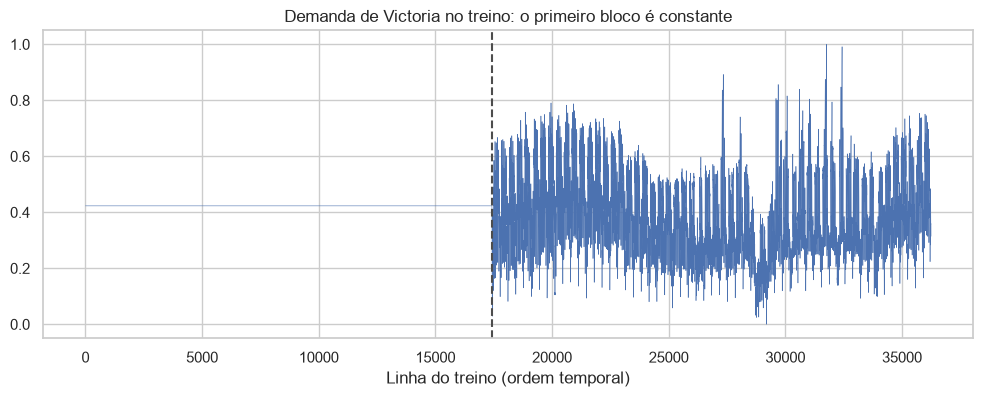

In [41]:
# Valores fixos que aparecem repetidos nas colunas de Victoria
valores_preenchidos = train[VIC_COLS].mode().iloc[0]

# True nas linhas em que as 3 colunas de Victoria têm o valor preenchido ao mesmo tempo
linha_preenchida = (train[VIC_COLS] == valores_preenchidos).all(axis=1)
posicoes_preenchidas = np.where(linha_preenchida)[0]
ultima_linha_preenchida = posicoes_preenchidas.max()

print(f"Victoria preenchida: {linha_preenchida.sum()} linhas ({linha_preenchida.mean():.1%} do treino), "
      f"da linha {posicoes_preenchidas.min()} à {ultima_linha_preenchida}")
print("Linhas assim no teste:", (test[VIC_COLS] == valores_preenchidos).all(axis=1).sum())

# Evidência visual
ax = train["vic_demand_normalized"].plot(figsize=(12, 4), linewidth=0.4,
        title="Demanda de Victoria no treino: o primeiro bloco é constante")
ax.axvline(ultima_linha_preenchida, color="0.3", linestyle="--")
ax.set_xlabel("Linha do treino (ordem temporal)")
plt.show()

### Faltantes disfarçados nas colunas de Victoria

A verificação de nulos (`isna()`) não encontrou nenhum valor ausente. Porém, ao analisar as colunas de Victoria (`vic_price`, `vic_demand` e `transfer`), observou-se que:

- **17.424 linhas (48,1% do treino)** apresentam exatamente os mesmos valores nas três colunas.
- Essas linhas formam um **bloco contínuo no início da base** (linhas 0 a 17.423), o que corresponde a cerca de **363 dias**, praticamente o primeiro ano do período (maio/1996 a maio/1997).
- O conjunto de **teste não possui** nenhuma linha com esse padrão.

Em um mercado de energia real, preço e demanda variam a cada meia-hora, então valores idênticos durante um ano inteiro não são plausíveis. Conclui-se que **os dados de Victoria não estavam disponíveis nesse período** e foram preenchidos com um valor fixo. Trata-se de um **valor faltante disfarçado**: existe um número na célula, por isso o `isna()` não o detecta, mas ele não representa uma medição real.

**Impactos:**
1. Quase metade do treino tem 3 das 5 variáveis numéricas sem informação real.
2. Como o teste não tem esse bloco, um modelo que aprenda padrões a partir dele pode não generalizar para o período avaliado.
3. O acúmulo de valores idênticos distorce estatísticas como quartis e, consequentemente, a detecção de outliers (analisada mais adiante).

In [42]:
# 1 = Victoria sem dado real (bloco preenchido); 0 = dado real
for base in (train, test):
    base["vic_sem_dado"] = (base[VIC_COLS] == valores_preenchidos).all(axis=1).astype(int)

print("vic_sem_dado no treino:", train["vic_sem_dado"].value_counts().to_dict())
print("vic_sem_dado no teste: ", test["vic_sem_dado"].value_counts().to_dict())

taxa_queda_por_grupo = y_train.groupby(train["vic_sem_dado"]).mean().round(3)
print("\nTaxa de queda por grupo (treino):")
print(taxa_queda_por_grupo)

vic_sem_dado no treino: {0: 18816, 1: 17424}
vic_sem_dado no teste:  {0: 9072}

Taxa de queda por grupo (treino):
vic_sem_dado
0    0.600
1    0.563
Name: nsw_price_class, dtype: float64


### Decisão: tratamento dos faltantes disfarçados

| Opção | Vantagem | Desvantagem |
|---|---|---|
| Remover as 17.424 linhas | Treino só com dados reais | Perde 48% do treino, incluindo as informações de NSW, que são reais nesse período |
| Imputar (média ou interpolação) | Mantém todas as linhas | Seria inventar um ano inteiro de dados de Victoria; não há valores vizinhos para interpolar |
| Remover as colunas de Victoria | Simples | Descarta informação real do restante do treino e de todo o teste |
| **Manter + variável indicadora** | **Preserva os dados de NSW e permite ao modelo distinguir os dois períodos** | A indicadora é sempre 0 no teste |

**Decisão adotada:** manter as linhas e criar a variável `vic_sem_dado` (1 = Victoria sem dado real, 0 = dado real). Com ela, o modelo pode aprender que, quando `vic_sem_dado = 1`, os valores de Victoria não carregam informação. No teste, como todas as linhas têm dados reais, o modelo usa o comportamento aprendido no período completo.

Como verificação, na etapa de modelagem será feito um **experimento comparativo**: treinar com a base inteira (com a indicadora) e treinar apenas com o período completo (`vic_sem_dado = 0`), avaliando qual estratégia gera melhores resultados na validação.

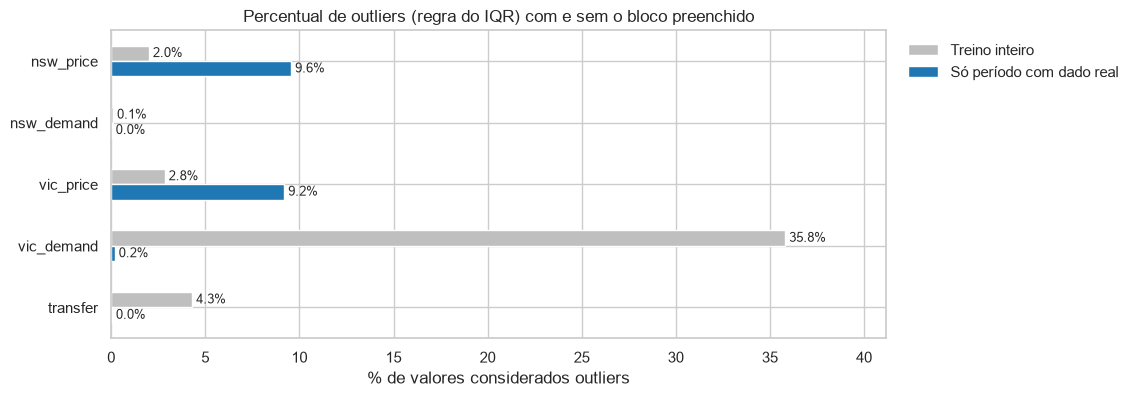

In [43]:
def percentual_outliers(dados):
    """% de valores fora do intervalo [Q1 - 1,5·IQR, Q3 + 1,5·IQR] em cada coluna."""
    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    iqr = q3 - q1
    fora_do_intervalo = (dados < q1 - 1.5 * iqr) | (dados > q3 + 1.5 * iqr)
    return fora_do_intervalo.mean() * 100

periodo_completo = train[train["vic_sem_dado"] == 0]

comparacao_outliers = pd.DataFrame({
    "Treino inteiro":            percentual_outliers(train[NUM_COLS]),
    "Só período com dado real":  percentual_outliers(periodo_completo[NUM_COLS]),
}).rename(index=lambda coluna: coluna.replace("_normalized", ""))

ax = comparacao_outliers.plot.barh(figsize=(10, 4), color=["0.75", "tab:blue"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, comparacao_outliers.values.max() * 1.15)
ax.set_title("Percentual de outliers (regra do IQR) com e sem o bloco preenchido")
ax.set_xlabel("% de valores considerados outliers")
ax.set_ylabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

### Outliers

A detecção de outliers foi feita pela **regra do IQR**: um valor é considerado outlier quando fica abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR, isto é, muito afastado da faixa onde está a metade central dos dados.

**Efeito do bloco preenchido:** no treino inteiro, cerca de **36%** dos valores de `vic_demand` foram marcados como outliers. Considerando apenas o período com dados reais de Victoria, esse percentual cai para **0,2%**. Isso acontece porque metade dos valores está concentrada em um único número (o valor de preenchimento), o que estreita artificialmente a faixa entre Q1 e Q3 e faz variações normais parecerem anormais. Portanto, a análise de outliers deve considerar o período com dados reais.

**Outliers reais:** mesmo no período com dados reais, cerca de **9%** dos preços de NSW e de Victoria ficam fora da faixa, quase sempre acima dela. Esses valores correspondem a **picos de preço**, comuns em mercados de energia quando a demanda está alta ou a oferta está baixa. Não são erros de medição.

**Decisão adotada:** **manter os outliers**, pelos seguintes motivos:
1. São valores reais do mercado, e não erros de coleta.
2. Removê-los apagaria justamente os momentos mais extremos do fenômeno que se quer prever.